Found 2 photopeaks at rough voltages: [0.6769 0.7854]
Peak 1 near 0.677 V -> Exact Centroid = 0.6860 V
Peak 2 near 0.785 V -> Exact Centroid = 0.7849 V


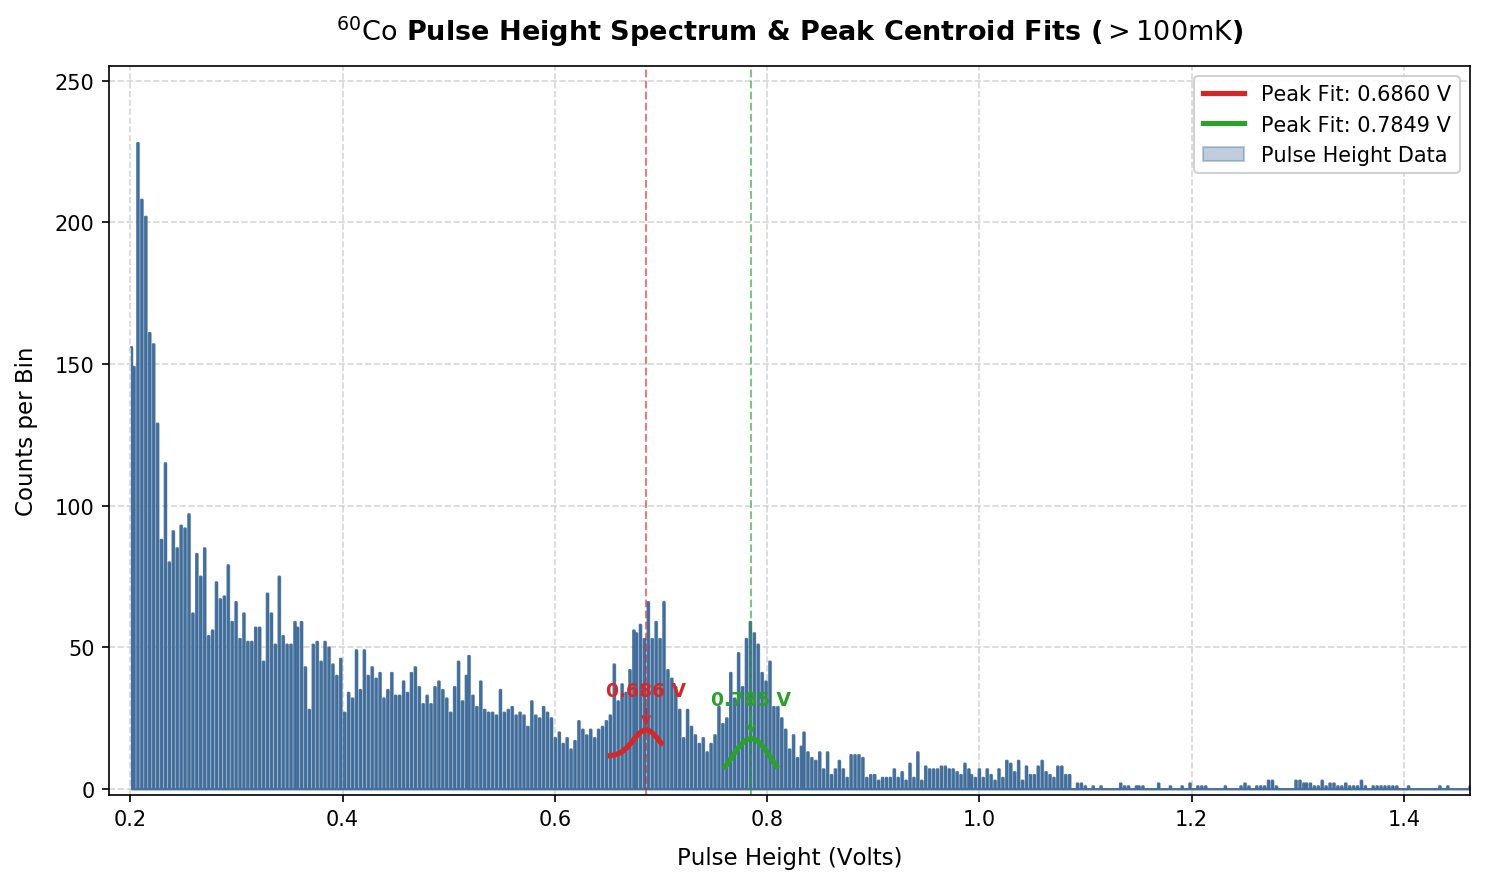


Final Exact Voltages for Calibration:
[0.68597912 0.78492952]


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d

# ==========================================
# 1. Define Functions
# ==========================================
def gaussian_bg(x, amp, mean, sigma, bg):
    """Robust 4-parameter Gaussian peak model with local background."""
    return amp * np.exp(-((x - mean)**2) / (2 * sigma**2)) + bg

def butter_bandpass_filter(data, lowcut=0.01, highcut=0.2, fs=1.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# ==========================================
# 2. Load & Clean CSV Data
# ==========================================
csv_filename = 'new_co60_above_100K.csv'
target_column = 'pulse_height_V'
min_voltage = 0.2  # Minimum voltage threshold

try:
    df = pd.read_csv(csv_filename, comment='#', on_bad_lines='skip')
except TypeError:
    df = pd.read_csv(csv_filename, comment='#', error_bad_lines=False, warn_bad_lines=False)

df.columns = df.columns.astype(str).str.strip()

if target_column in df.columns:
    raw_series = df[target_column]
else:
    raw_series = df.iloc[:, 0]

clean_series = pd.to_numeric(raw_series, errors='coerce').dropna()
voltages = clean_series[np.isfinite(clean_series)].values.astype(float)
voltages = voltages[voltages >= min_voltage]

# Define channels
num_channels = 1024 
counts, bin_edges = np.histogram(voltages, bins=num_channels)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# ==========================================
# 3. Peak Detection in Photopeak ROI (V >= 0.45 V)
# ==========================================
filtered_counts = butter_bandpass_filter(counts, lowcut=0.01, highcut=0.2, fs=1.0, order=3)
smoothed_counts = gaussian_filter1d(filtered_counts, sigma=3)

# Restrict peak search to voltages >= 0.45 V to ignore low-energy continuum edge artifacts
roi_mask = (bin_centers >= 0.45)
roi_indices = np.where(roi_mask)[0]

peaks_in_roi, _ = find_peaks(
    smoothed_counts[roi_mask], 
    height=5,        # Threshold for baseline-subtracted filtered data
    distance=25,     # Bin separation between peaks (~0.03 V)
    prominence=5
)

# Map back to global array indices
rough_peak_indices = roi_indices[peaks_in_roi]

print(f"Found {len(rough_peak_indices)} photopeaks at rough voltages: {np.round(bin_centers[rough_peak_indices], 4)}")

# ==========================================
# 4. Centroid Fitting (Using RAW Counts)
# ==========================================
exact_voltage_centroids = []
fit_window = 20  # Bins on each side of peak
colors = ['#d62728', '#2ca02c', '#9467bd', '#ff7f0e']

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Shaded histogram fill for raw spectrum
ax.fill_between(bin_centers, counts, step="mid", alpha=0.3, color="#2b5c8f", label="Pulse Height Data")
ax.step(bin_centers, counts, where="mid", color="#2b5c8f", linewidth=1.0, alpha=0.8)

for i, p_idx in enumerate(rough_peak_indices):
    start = max(0, p_idx - fit_window)
    end = min(num_channels, p_idx + fit_window)
    
    x_fit = bin_centers[start:end]
    y_fit = counts[start:end]  # Sliced directly from RAW counts
    
    # Stable initial parameter estimates
    guess_amp = max(0.0, float(np.max(y_fit) - np.min(y_fit)))
    guess_mean = float(bin_centers[p_idx])
    guess_sigma = 0.015
    guess_bg = max(0.0, float(np.min(y_fit)))
    
    p0 = [guess_amp, guess_mean, guess_sigma, guess_bg]
    
    # Bounds: [amplitude >= 0, mean in window, 0.002 <= sigma <= 0.1 V, background >= 0]
    lower_bounds = [0.0, x_fit[0], 0.002, 0.0]
    upper_bounds = [np.inf, x_fit[-1], 0.1, np.inf]
    
    try:
        popt, _ = curve_fit(
            gaussian_bg, 
            x_fit, 
            y_fit, 
            p0=p0, 
            bounds=(lower_bounds, upper_bounds), 
            maxfev=10000
        )
        fitted_voltage = popt[1]
        exact_voltage_centroids.append(fitted_voltage)
        
        print(f"Peak {i+1} near {bin_centers[p_idx]:.3f} V -> Exact Centroid = {fitted_voltage:.4f} V")
        
        # Plot fitted curve sitting directly on raw data
        x_plot = np.linspace(x_fit[0], x_fit[-1], 100)
        y_plot = gaussian_bg(x_plot, *popt)
        c = colors[i % len(colors)]
        
        ax.plot(x_plot, y_plot, color=c, linewidth=2.5, label=f'Peak Fit: {fitted_voltage:.4f} V')
        ax.axvline(fitted_voltage, color=c, linestyle='--', alpha=0.6, linewidth=1)
        
        # Text annotation above peak
        ax.annotate(f"{fitted_voltage:.3f} V",
                    xy=(fitted_voltage, np.max(y_plot)),
                    xytext=(fitted_voltage, np.max(y_plot) + 12),
                    ha='center', fontsize=9, fontweight='bold', color=c,
                    arrowprops=dict(arrowstyle="->", color=c, lw=1))
        
    except RuntimeError:
        print(f"Fit failed for peak at channel index {p_idx}.")

# ==========================================
# 5. Styling & Output
# ==========================================
ax.set_title(r"$^{60}\mathrm{Co}$ Pulse Height Spectrum & Peak Centroid Fits ($>100\mathrm{mK}$)", 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Pulse Height (Volts)", fontsize=11, labelpad=8)
ax.set_ylabel("Counts per Bin", fontsize=11, labelpad=8)
ax.set_xlim(min_voltage - 0.02, np.max(bin_centers))
ax.set_ylim(-2, np.max(counts) * 1.12)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10, loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nFinal Exact Voltages for Calibration:")
print(np.array(exact_voltage_centroids))

Found 3 photopeaks at rough voltages: [0.534  0.6581 0.7643]
Peak 1 near 0.534 V -> Exact Centroid = 0.5287 V
Peak 2 near 0.658 V -> Exact Centroid = 0.6680 V
Peak 3 near 0.764 V -> Exact Centroid = 0.7596 V


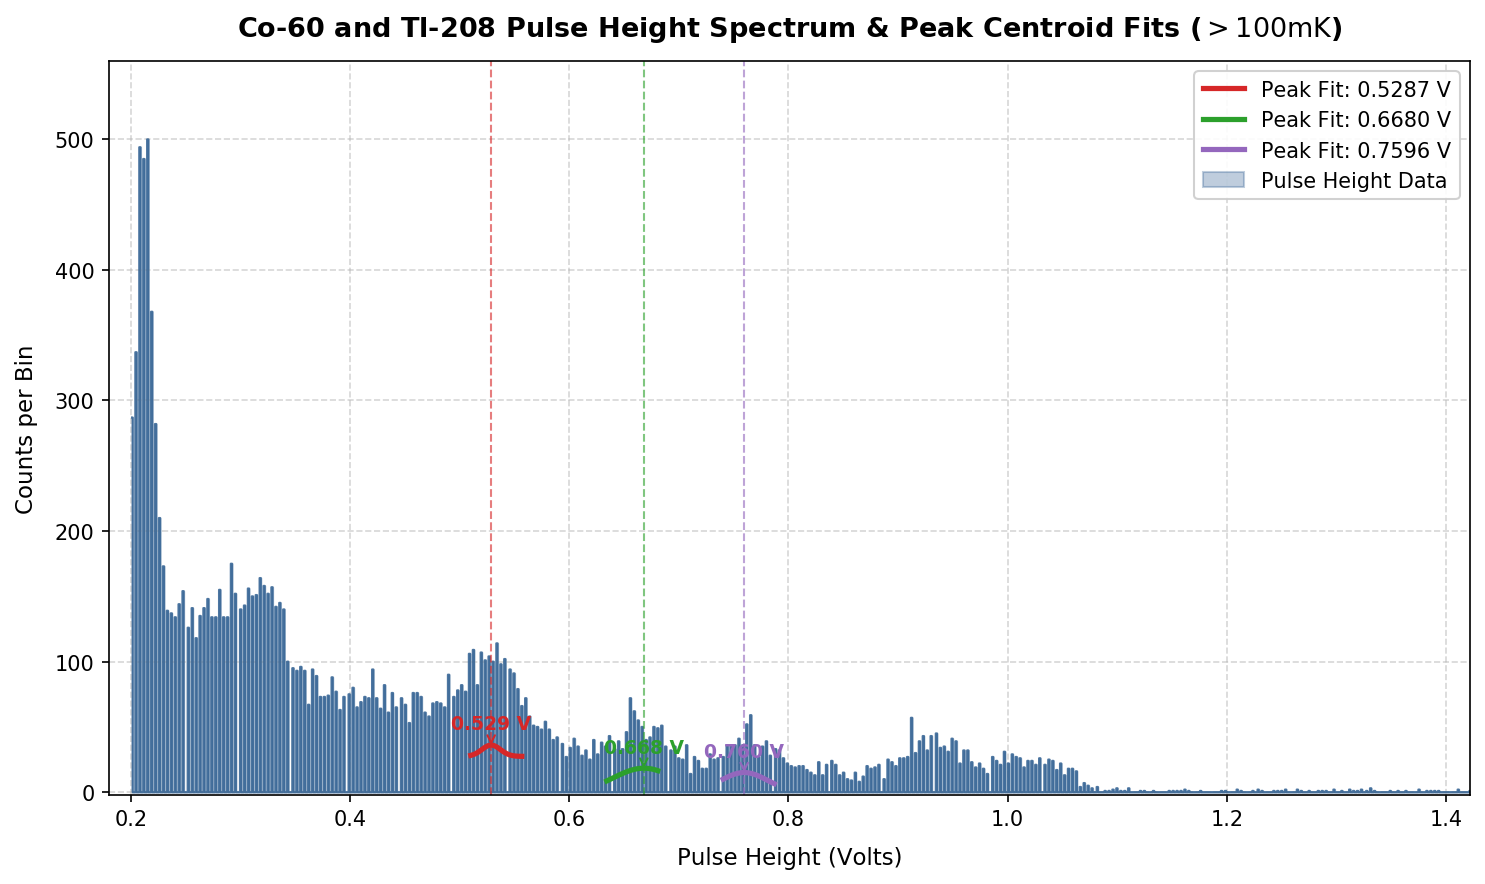


Final Exact Voltages for Calibration:
[0.52871056 0.66801834 0.75962358]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d

# ==========================================
# 1. Define Functions
# ==========================================
def gaussian_bg(x, amp, mean, sigma, bg):
    """Robust 4-parameter Gaussian peak model with local background."""
    return amp * np.exp(-((x - mean)**2) / (2 * sigma**2)) + bg

def butter_bandpass_filter(data, lowcut=0.01, highcut=0.2, fs=1.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# ==========================================
# 2. Load & Clean CSV Data
# ==========================================
csv_filename = 'co60_th232_above100K.csv'
target_column = 'pulse_height_V'
min_voltage = 0.2  # Minimum voltage threshold

try:
    df = pd.read_csv(csv_filename, comment='#', on_bad_lines='skip')
except TypeError:
    df = pd.read_csv(csv_filename, comment='#', error_bad_lines=False, warn_bad_lines=False)

df.columns = df.columns.astype(str).str.strip()

if target_column in df.columns:
    raw_series = df[target_column]
else:
    raw_series = df.iloc[:, 0]

clean_series = pd.to_numeric(raw_series, errors='coerce').dropna()
voltages = clean_series[np.isfinite(clean_series)].values.astype(float)
voltages = voltages[voltages >= min_voltage]

# Define channels
num_channels = 1024 
counts, bin_edges = np.histogram(voltages, bins=num_channels)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# ==========================================
# 3. Peak Detection in Photopeak ROI (V >= 0.45 V)
# ==========================================
filtered_counts = butter_bandpass_filter(counts, lowcut=0.01, highcut=0.2, fs=1.0, order=3)
smoothed_counts = gaussian_filter1d(filtered_counts, sigma=3)

# Restrict peak search to voltages >= 0.45 V to ignore low-energy continuum edge artifacts
roi_mask = (bin_centers >= 0.45)
roi_indices = np.where(roi_mask)[0]

peaks_in_roi, _ = find_peaks(
    smoothed_counts[roi_mask], 
    height=5,        # Threshold for baseline-subtracted filtered data
    distance=25,     # Bin separation between peaks (~0.03 V)
    prominence=5
)

# Map back to global array indices
rough_peak_indices = roi_indices[peaks_in_roi]

print(f"Found {len(rough_peak_indices)} photopeaks at rough voltages: {np.round(bin_centers[rough_peak_indices], 4)}")

# ==========================================
# 4. Centroid Fitting (Using RAW Counts)
# ==========================================
exact_voltage_centroids = []
fit_window = 20  # Bins on each side of peak
colors = ['#d62728', '#2ca02c', '#9467bd', '#ff7f0e']

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Shaded histogram fill for raw spectrum
ax.fill_between(bin_centers, counts, step="mid", alpha=0.3, color="#2b5c8f", label="Pulse Height Data")
ax.step(bin_centers, counts, where="mid", color="#2b5c8f", linewidth=1.0, alpha=0.8)

for i, p_idx in enumerate(rough_peak_indices):
    start = max(0, p_idx - fit_window)
    end = min(num_channels, p_idx + fit_window)
    
    x_fit = bin_centers[start:end]
    y_fit = counts[start:end]  # Sliced directly from RAW counts
    
    # Stable initial parameter estimates
    guess_amp = max(0.0, float(np.max(y_fit) - np.min(y_fit)))
    guess_mean = float(bin_centers[p_idx])
    guess_sigma = 0.015
    guess_bg = max(0.0, float(np.min(y_fit)))
    
    p0 = [guess_amp, guess_mean, guess_sigma, guess_bg]
    
    # Bounds: [amplitude >= 0, mean in window, 0.002 <= sigma <= 0.1 V, background >= 0]
    lower_bounds = [0.0, x_fit[0], 0.002, 0.0]
    upper_bounds = [np.inf, x_fit[-1], 0.1, np.inf]
    
    try:
        popt, _ = curve_fit(
            gaussian_bg, 
            x_fit, 
            y_fit, 
            p0=p0, 
            bounds=(lower_bounds, upper_bounds), 
            maxfev=10000
        )
        fitted_voltage = popt[1]
        exact_voltage_centroids.append(fitted_voltage)
        
        print(f"Peak {i+1} near {bin_centers[p_idx]:.3f} V -> Exact Centroid = {fitted_voltage:.4f} V")
        
        # Plot fitted curve sitting directly on raw data
        x_plot = np.linspace(x_fit[0], x_fit[-1], 100)
        y_plot = gaussian_bg(x_plot, *popt)
        c = colors[i % len(colors)]
        
        ax.plot(x_plot, y_plot, color=c, linewidth=2.5, label=f'Peak Fit: {fitted_voltage:.4f} V')
        ax.axvline(fitted_voltage, color=c, linestyle='--', alpha=0.6, linewidth=1)
        
        # Text annotation above peak
        ax.annotate(f"{fitted_voltage:.3f} V",
                    xy=(fitted_voltage, np.max(y_plot)),
                    xytext=(fitted_voltage, np.max(y_plot) + 12),
                    ha='center', fontsize=9, fontweight='bold', color=c,
                    arrowprops=dict(arrowstyle="->", color=c, lw=1))
        
    except RuntimeError:
        print(f"Fit failed for peak at channel index {p_idx}.")

# ==========================================
# 5. Styling & Output
# ==========================================
ax.set_title(r"Co-60 and Th-232 Pulse Height Spectrum & Peak Centroid Fits ($>100\mathrm{mK}$)", 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Pulse Height (Volts)", fontsize=11, labelpad=8)
ax.set_ylabel("Counts per Bin", fontsize=11, labelpad=8)
ax.set_xlim(min_voltage - 0.02, np.max(bin_centers))
ax.set_ylim(-2, np.max(counts) * 1.12)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10, loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nFinal Exact Voltages for Calibration:")
print(np.array(exact_voltage_centroids))

Found 1 photopeaks at rough voltages: [0.8599]
Peak 1 near 0.860 V -> Exact Centroid = 0.8363 V


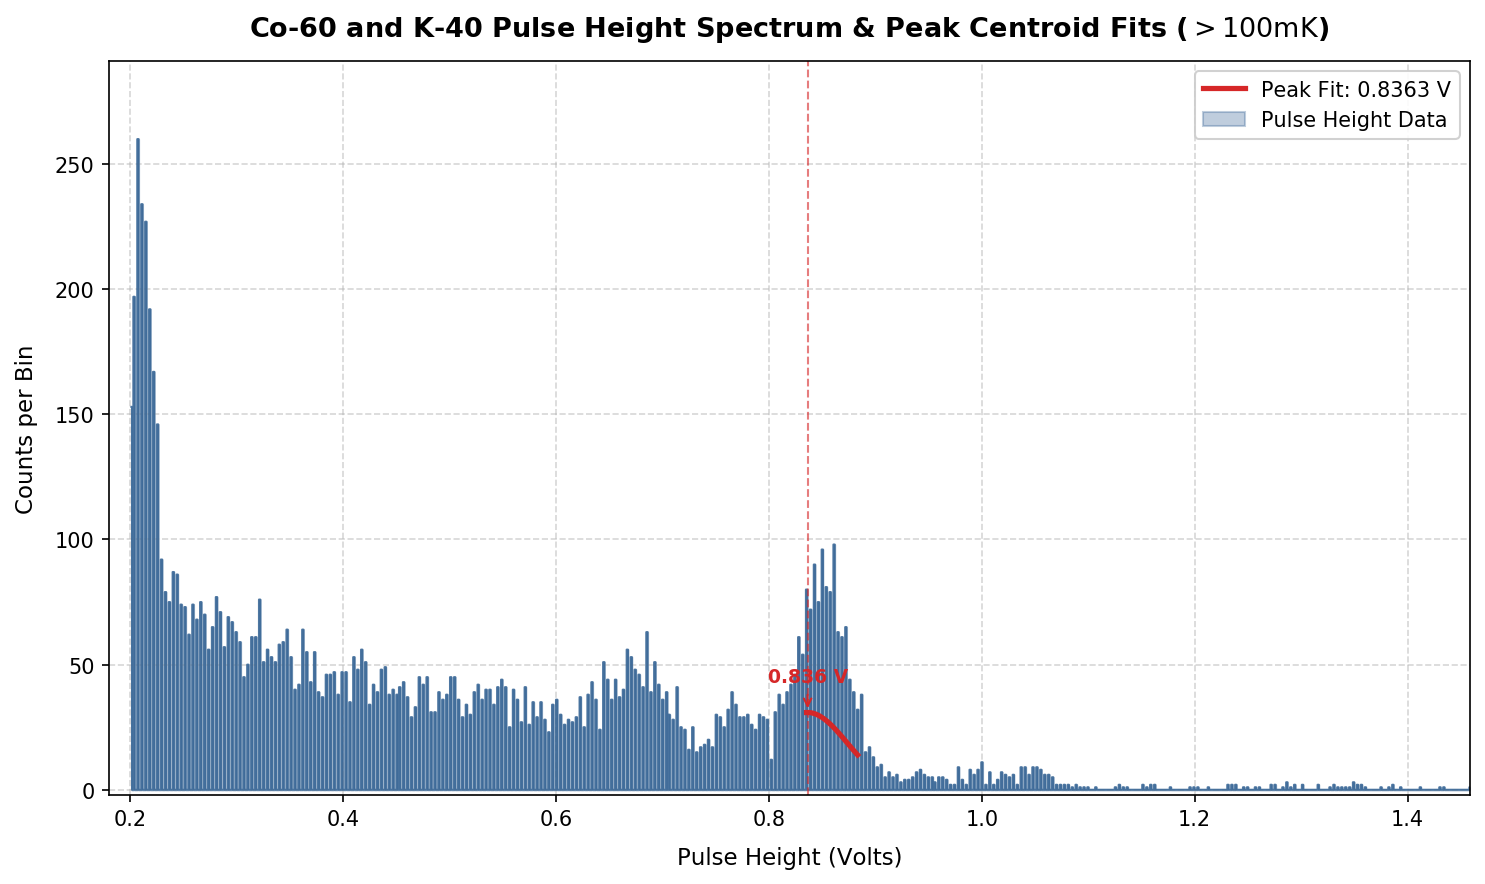


Final Exact Voltages for Calibration:
[0.8362936]


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d

# ==========================================
# 1. Define Functions
# ==========================================
def gaussian_bg(x, amp, mean, sigma, bg):
    """Robust 4-parameter Gaussian peak model with local background."""
    return amp * np.exp(-((x - mean)**2) / (2 * sigma**2)) + bg

def butter_bandpass_filter(data, lowcut=0.01, highcut=0.2, fs=1.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# ==========================================
# 2. Load & Clean CSV Data
# ==========================================
csv_filename = 'co60_k40_true.csv'
target_column = 'pulse_height_V'
min_voltage = 0.2  # Minimum voltage threshold

try:
    df = pd.read_csv(csv_filename, comment='#', on_bad_lines='skip')
except TypeError:
    df = pd.read_csv(csv_filename, comment='#', error_bad_lines=False, warn_bad_lines=False)

df.columns = df.columns.astype(str).str.strip()

if target_column in df.columns:
    raw_series = df[target_column]
else:
    raw_series = df.iloc[:, 0]

clean_series = pd.to_numeric(raw_series, errors='coerce').dropna()
voltages = clean_series[np.isfinite(clean_series)].values.astype(float)
voltages = voltages[voltages >= min_voltage]

# Define channels
num_channels = 1024 
counts, bin_edges = np.histogram(voltages, bins=num_channels)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# ==========================================
# 3. Peak Detection in Photopeak ROI (V >= 0.45 V)
# ==========================================
filtered_counts = butter_bandpass_filter(counts, lowcut=0.01, highcut=0.2, fs=1.0, order=3)
smoothed_counts = gaussian_filter1d(filtered_counts, sigma=3)

# Restrict peak search to voltages >= 0.45 V to ignore low-energy continuum edge artifacts
roi_mask = (bin_centers >= 0.45)
roi_indices = np.where(roi_mask)[0]

peaks_in_roi, _ = find_peaks(
    smoothed_counts[roi_mask], 
    height=5,        # Threshold for baseline-subtracted filtered data
    distance=25,     # Bin separation between peaks (~0.03 V)
    prominence=5
)

# Map back to global array indices
rough_peak_indices = roi_indices[peaks_in_roi]

print(f"Found {len(rough_peak_indices)} photopeaks at rough voltages: {np.round(bin_centers[rough_peak_indices], 4)}")

# ==========================================
# 4. Centroid Fitting (Using RAW Counts)
# ==========================================
exact_voltage_centroids = []
fit_window = 20  # Bins on each side of peak
colors = ['#d62728', '#2ca02c', '#9467bd', '#ff7f0e']

fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# Shaded histogram fill for raw spectrum
ax.fill_between(bin_centers, counts, step="mid", alpha=0.3, color="#2b5c8f", label="Pulse Height Data")
ax.step(bin_centers, counts, where="mid", color="#2b5c8f", linewidth=1.0, alpha=0.8)

for i, p_idx in enumerate(rough_peak_indices):
    start = max(0, p_idx - fit_window)
    end = min(num_channels, p_idx + fit_window)
    
    x_fit = bin_centers[start:end]
    y_fit = counts[start:end]  # Sliced directly from RAW counts
    
    # Stable initial parameter estimates
    guess_amp = max(0.0, float(np.max(y_fit) - np.min(y_fit)))
    guess_mean = float(bin_centers[p_idx])
    guess_sigma = 0.015
    guess_bg = max(0.0, float(np.min(y_fit)))
    
    p0 = [guess_amp, guess_mean, guess_sigma, guess_bg]
    
    # Bounds: [amplitude >= 0, mean in window, 0.002 <= sigma <= 0.1 V, background >= 0]
    lower_bounds = [0.0, x_fit[0], 0.002, 0.0]
    upper_bounds = [np.inf, x_fit[-1], 0.1, np.inf]
    
    try:
        popt, _ = curve_fit(
            gaussian_bg, 
            x_fit, 
            y_fit, 
            p0=p0, 
            bounds=(lower_bounds, upper_bounds), 
            maxfev=10000
        )
        fitted_voltage = popt[1]
        exact_voltage_centroids.append(fitted_voltage)
        
        print(f"Peak {i+1} near {bin_centers[p_idx]:.3f} V -> Exact Centroid = {fitted_voltage:.4f} V")
        
        # Plot fitted curve sitting directly on raw data
        x_plot = np.linspace(x_fit[0], x_fit[-1], 100)
        y_plot = gaussian_bg(x_plot, *popt)
        c = colors[i % len(colors)]
        
        ax.plot(x_plot, y_plot, color=c, linewidth=2.5, label=f'Peak Fit: {fitted_voltage:.4f} V')
        ax.axvline(fitted_voltage, color=c, linestyle='--', alpha=0.6, linewidth=1)
        
        # Text annotation above peak
        ax.annotate(f"{fitted_voltage:.3f} V",
                    xy=(fitted_voltage, np.max(y_plot)),
                    xytext=(fitted_voltage, np.max(y_plot) + 12),
                    ha='center', fontsize=9, fontweight='bold', color=c,
                    arrowprops=dict(arrowstyle="->", color=c, lw=1))
        
    except RuntimeError:
        print(f"Fit failed for peak at channel index {p_idx}.")

# ==========================================
# 5. Styling & Output
# ==========================================
ax.set_title(r"Co-60 and K-40 Pulse Height Spectrum & Peak Centroid Fits ($>100\mathrm{mK}$)", 
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Pulse Height (Volts)", fontsize=11, labelpad=8)
ax.set_ylabel("Counts per Bin", fontsize=11, labelpad=8)
ax.set_xlim(min_voltage - 0.02, np.max(bin_centers))
ax.set_ylim(-2, np.max(counts) * 1.12)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10, loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\nFinal Exact Voltages for Calibration:")
print(np.array(exact_voltage_centroids))

--- Linear Calibration Results ---
Slope (m):          1.7444 +/- 0.0831 MeV/V
Intercept (c):      -0.0091 +/- 0.0596 MeV
Chi-Squared:        4.086
Degrees of Freedom: 4
Reduced Chi-Squared:1.021



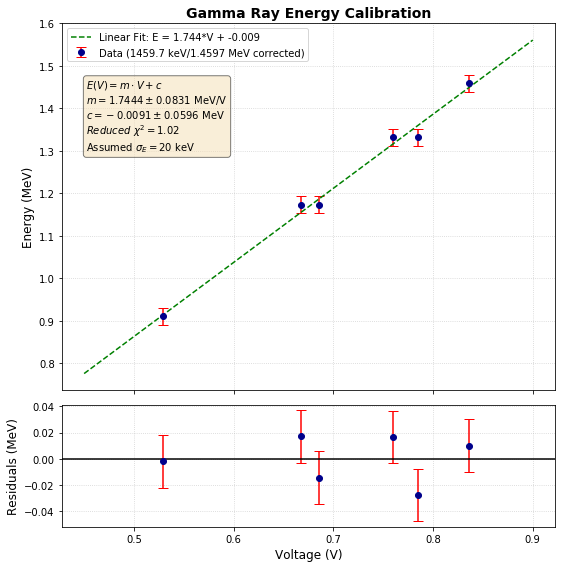

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the experimental data points extracted from the three spectrums
# Voltages (V) and corrected energy peaks (MeV)
voltages = np.array([0.5287, 0.6680, 0.6860, 0.7596, 0.7849, 0.8363])
energies = np.array([0.9112, 1.1732, 1.1732, 1.3325, 1.3325, 1.4597])

# Define the peak uncertainty (sigma) - assumed to be 20 keV (0.02 MeV)
energy_errors = np.full_like(energies, 0.02)

# 2. Perform a weighted linear fit (y = m * x + c)
# Weights are defined as 1 / sigma^2
weights = 1.0 / (energy_errors**2)
coefs, cov = np.polyfit(voltages, energies, 1, w=weights, cov=True)
m, c = coefs
m_err, c_err = np.sqrt(np.diag(cov))

# Calculate fit predictions and residuals
energies_pred = m * voltages + c
residuals = energies - energies_pred

# 3. Calculate Chi-Squared statistics
chi2 = np.sum((residuals / energy_errors)**2)
ndof = len(voltages) - 2
reduced_chi2 = chi2 / ndof

# Display the fit parameters in the terminal
print("--- Linear Calibration Results ---")
print(f"Slope (m):          {m:.4f} +/- {m_err:.4f} MeV/V")
print(f"Intercept (c):      {c:.4f} +/- {c_err:.4f} MeV")
print(f"Chi-Squared:        {chi2:.3f}")
print(f"Degrees of Freedom: {ndof}")
print(f"Reduced Chi-Squared:{reduced_chi2:.3f}\n")

# 4. Create the dual-plot figure (Calibration Fit + Residuals)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# --- Top Plot: Calibration Fit ---
# Plot raw data points with error bars
ax1.errorbar(voltages, energies, yerr=energy_errors, fmt='o', color='darkblue', 
             ecolor='red', capsize=5, label='Data (1459.7 keV/1.4597 MeV corrected)')

# Plot linear fit line
x_fit = np.linspace(0.45, 0.90, 100)
y_fit = m * x_fit + c
ax1.plot(x_fit, y_fit, color='green', linestyle='--', 
         label=f'Linear Fit: E = {m:.3f}*V + {c:.3f}')

ax1.set_ylabel('Energy (MeV)', fontsize=12)
ax1.set_title('Gamma Ray Energy Calibration', fontsize=14, fontweight='bold')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.6)

# Annotate the plot with fit statistics
textstr = '\n'.join((
    r'$E(V) = m \cdot V + c$',
    rf'$m = {m:.4f} \pm {m_err:.4f}\ \mathrm{{MeV/V}}$',
    rf'$c = {c:.4f} \pm {c_err:.4f}\ \mathrm{{MeV}}$',
    rf'$Reduced\ \chi^2 = {reduced_chi2:.2f}$',
    r'Assumed $\sigma_E = 20\ \mathrm{{keV}}$'
))
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax1.text(0.05, 0.85, textstr, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', bbox=props)

# --- Bottom Plot: Residuals ---
# Plot residual values with error bars
ax2.errorbar(voltages, residuals, yerr=energy_errors, fmt='o', color='darkblue', ecolor='red', capsize=5)
ax2.axhline(0, color='black', linestyle='-')
ax2.set_xlabel('Voltage (V)', fontsize=12)
ax2.set_ylabel('Residuals (MeV)', fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

# Final formatting adjustments
plt.tight_layout()
plt.show()

In [6]:
import pathlib
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ==============================================================================
# 1. CALIBRATION PARAMETERS
# ==============================================================================
# Linear fit: E(V) = m * V + c derived from image calibration
CALIB_M = 1.7444  # MeV / V[cite: 1]
CALIB_C = -0.0091  # MeV[cite: 1]


# ==============================================================================
# 2. DATA LOADING & BINNING
# ==============================================================================

def load_and_bin_spectrum(filepath, bin_edges, raw_voltage=False):
    """
    Parses a single list-mode CSV spectrum file.

    If raw_voltage=True, bins raw voltages directly.
    Otherwise, converts voltages to MeV using CALIB_M and CALIB_C before binning.
    """
    voltages = []

    with open(filepath, 'r') as f:
        next(f)  # Skip header
        for line in f:
            parts = line.strip().split(',')
            if len(parts) >= 1:
                try:
                    voltages.append(float(parts[-1]))
                except ValueError:
                    continue

    voltages_arr = np.array(voltages)

    if raw_voltage:
        # Bin raw voltages directly
        counts, _ = np.histogram(voltages_arr, bins=bin_edges)
    else:
        # Convert voltages to energies (MeV) and bin
        event_energies = CALIB_M * voltages_arr + CALIB_C
        counts, _ = np.histogram(event_energies, bins=bin_edges)

    return counts


# ==============================================================================
# 3. INTERACTIVE PLOTTING (SINGLE FILE)
# ==============================================================================

def show_interactive_spectrum(filepath, v_min=0.0, v_max=2.2, num_bins=10000):
    """
    Generates an interactive Plotly histogram for a single spectrum file
    converting Voltage bin edges to MeV using linear calibration.
    """
    filepath = pathlib.Path(filepath)

    # 1. Create voltage bin edges and convert to MeV via calibration
    v_edges = np.linspace(v_min, v_max, num_bins)
    bin_edges = CALIB_M * v_edges + CALIB_C
    energies = (bin_edges[:-1] + bin_edges[1:]) / 2

    # 2. Load and bin single file data
    counts = load_and_bin_spectrum(filepath, bin_edges, raw_voltage=False)

    # 3. Create interactive Plotly figure
    fig = go.Figure(data=go.Scatter(
        x=energies,
        y=counts,
        mode='lines',
        line_shape='hvh',
        fill='tozeroy',
        name='Counts',
        line=dict(width=1)
    ))

    fig.update_layout(
        title=f"Calibrated Spectrum: {filepath.name} (E = {CALIB_M}*V + {CALIB_C} MeV)",
        xaxis_title="Energy (MeV)",
        yaxis_title="Counts",
        template="plotly_dark",
        xaxis=dict(
            rangeslider=dict(visible=True),
            type="linear"
        ),
        yaxis=dict(fixedrange=False)
    )

    fig.show(config={'scrollZoom': True})


def show_interactive_spectrum_voltage(filepath, v_min=0.0, v_max=2.2, num_bins=10000):
    """
    Generates an interactive Plotly histogram for a single spectrum file
    using raw pulse height voltage bins.
    """
    filepath = pathlib.Path(filepath)

    # Create voltage bin edges and bin centers
    bin_edges = np.linspace(v_min, v_max, num_bins)
    voltages = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Load and bin single file raw voltage data
    counts = load_and_bin_spectrum(filepath, bin_edges, raw_voltage=True)

    fig = go.Figure(data=go.Scatter(
        x=voltages,
        y=counts,
        mode='lines',
        line_shape='hvh',
        fill='tozeroy',
        name='Counts',
        line=dict(width=1)
    ))

    fig.update_layout(
        title=f"Raw Voltage Spectrum: {filepath.name}",
        xaxis_title="Pulse Height (V)",
        yaxis_title="Counts",
        template="plotly_dark",
        xaxis=dict(
            rangeslider=dict(visible=True),
            type="linear"
        ),
        yaxis=dict(fixedrange=False)
    )

    fig.show(config={'scrollZoom': True})


# ==============================================================================
# 4. EXECUTION EXAMPLE
# ==============================================================================

if __name__ == "__main__":
    # Specify single file path
    sample_file = pathlib.Path("new_co60_above_100K.csv")
    # Interactive uncalibrated pulse-height spectrum (Voltage)
    show_interactive_spectrum_voltage(sample_file, v_min=0.2, v_max=1.5, num_bins=10000)
    # Interactive energy-calibrated spectrum (MeV)
    show_interactive_spectrum(sample_file, v_min=0.2, v_max=1.5, num_bins=1024)

    # Specify single file path
    sample_file = pathlib.Path("co60_15mK_front_cryostat.csv")
    # Interactive uncalibrated pulse-height spectrum (Voltage)
    show_interactive_spectrum_voltage(sample_file, v_min=0.2, v_max=1.5, num_bins=10000)
    # Interactive energy-calibrated spectrum (MeV)
    show_interactive_spectrum(sample_file, v_min=0.2, v_max=1.5, num_bins=10000)